In [1]:
from pathlib import Path
import ipaddress

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100

DATA_PATH = Path("csv/cybersecurity_dataset.csv")
df = pd.read_csv(DATA_PATH, na_values=["", " "], low_memory=False)

LABEL_ORDER = sorted(df["label"].unique())
df["label"] = pd.Categorical(df["label"], categories=LABEL_ORDER, ordered=True)


I0000 00:00:1778493531.360498  520839 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1778493531.398544  520839 pjrt_api.cc:95] PJRT_Api is set for device type gpu
I0000 00:00:1778493531.401947  520839 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1778493532.751307  520839 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
print("shape:", df.shape)
print("memory:", df.memory_usage(deep=True).sum() / 1024**2, "MiB")
display(df.dtypes.to_frame("dtype"))
with pd.option_context("display.max_columns", None):
    display(df.head(8))


shape: (747273, 17)
memory: 163.35696697235107 MiB


,dtype
frame.time_epoch,float64
ip.src,str
ip.dst,str
ip.proto,int64
frame.len,int64
tcp.srcport,float64
tcp.dstport,float64
tcp.flags.syn,float64
tcp.flags.ack,float64
tcp.flags.fin,float64


,frame.time_epoch,ip.src,ip.dst,ip.proto,frame.len,tcp.srcport,tcp.dstport,tcp.flags.syn,tcp.flags.ack,tcp.flags.fin,tcp.flags.reset,tcp.flags.push,udp.srcport,udp.dstport,icmp.type,icmp.code,label
0,1.777276e+09,10.0.0.43,127.0.0.1,6,54,3343.0,80.0,0.0,1.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,ack
1,1.777276e+09,10.0.0.43,127.0.0.1,6,54,3344.0,80.0,0.0,1.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,ack
2,1.777276e+09,10.0.0.43,127.0.0.1,6,54,3345.0,80.0,0.0,1.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,ack
3,1.777276e+09,10.0.0.43,127.0.0.1,6,54,3346.0,80.0,0.0,1.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,ack
4,1.777276e+09,10.0.0.43,127.0.0.1,6,54,3347.0,80.0,0.0,1.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,ack
5,1.777276e+09,10.0.0.43,127.0.0.1,6,54,3348.0,80.0,0.0,1.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,ack
6,1.777276e+09,10.0.0.43,127.0.0.1,6,54,3349.0,80.0,0.0,1.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,ack
7,1.777276e+09,10.0.0.43,127.0.0.1,6,54,3350.0,80.0,0.0,1.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,ack


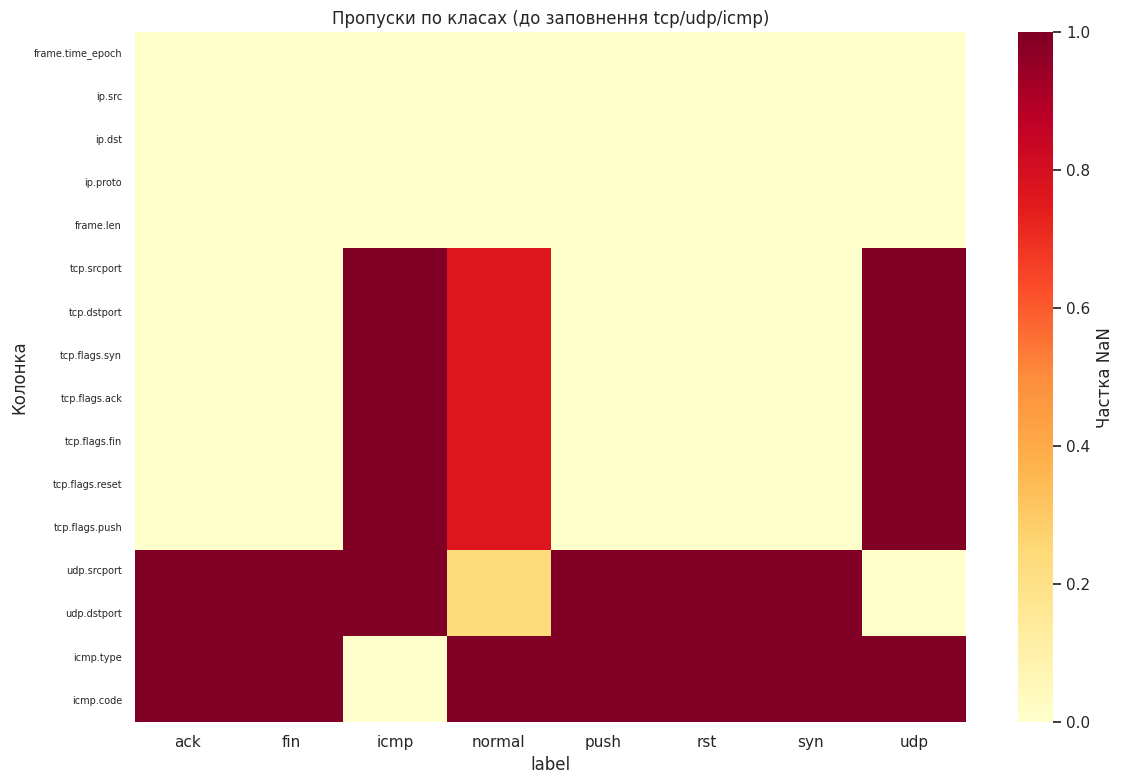

In [3]:
miss_by_label = df.groupby("label", observed=True).apply(
    lambda g: g.isna().mean(), include_groups=False
)
H = miss_by_label.T
n_rows = len(H)
plt.figure(figsize=(12, max(8, min(28, n_rows * 0.26))))
ax = sns.heatmap(H, cmap="YlOrRd", cbar_kws={"label": "Частка NaN"})
ax.set_yticklabels(ax.get_yticklabels(), fontsize=7, rotation=0)
plt.title("Пропуски по класах (до заповнення tcp/udp/icmp)")
plt.ylabel("Колонка")
plt.xlabel("label")
plt.tight_layout()
plt.show()

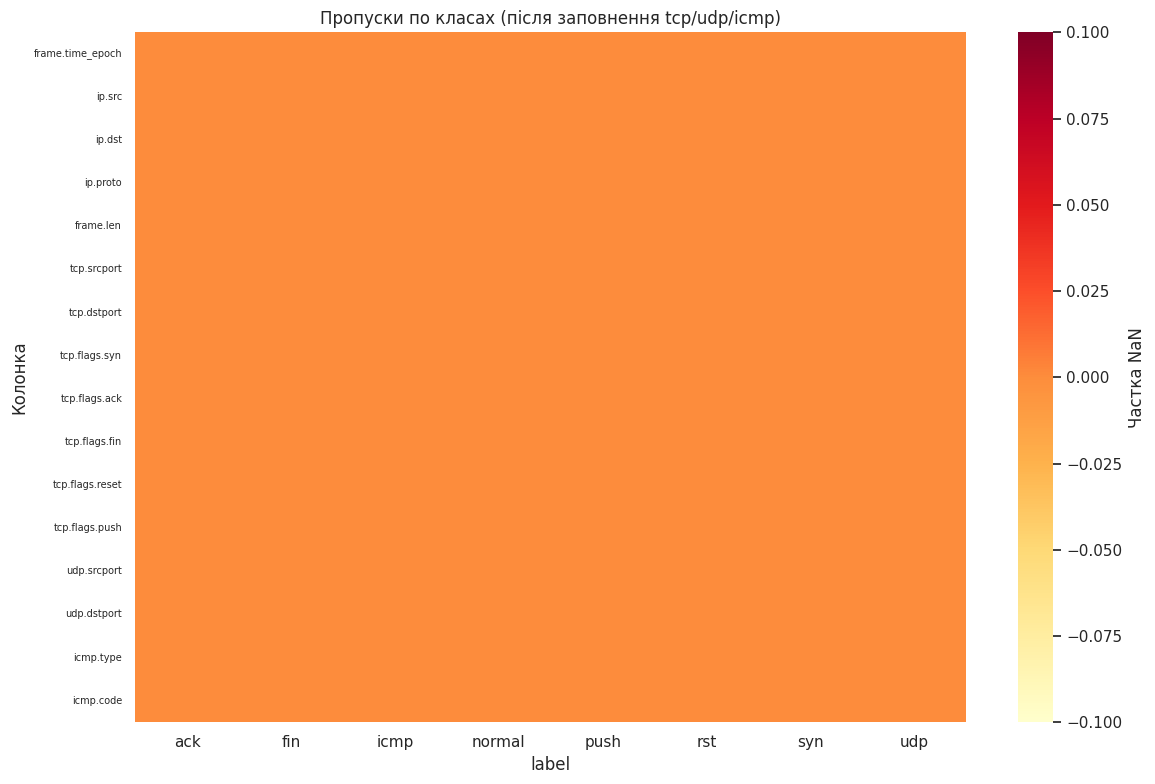

shape: (747273, 17)
memory: 163.35696697235107 MiB


,dtype
frame.time_epoch,float64
ip.src,str
ip.dst,str
ip.proto,int64
frame.len,int64
tcp.srcport,float64
tcp.dstport,float64
tcp.flags.syn,float64
tcp.flags.ack,float64
tcp.flags.fin,float64


,frame.time_epoch,ip.src,ip.dst,ip.proto,frame.len,tcp.srcport,tcp.dstport,tcp.flags.syn,tcp.flags.ack,tcp.flags.fin,tcp.flags.reset,tcp.flags.push,udp.srcport,udp.dstport,icmp.type,icmp.code,label
0,1.777276e+09,10.0.0.43,127.0.0.1,6,54,3343.0,80.0,0.0,1.0,0.0,0.0,0.0,-1.0,-1.0,-1.0,-1.0,ack
1,1.777276e+09,10.0.0.43,127.0.0.1,6,54,3344.0,80.0,0.0,1.0,0.0,0.0,0.0,-1.0,-1.0,-1.0,-1.0,ack
2,1.777276e+09,10.0.0.43,127.0.0.1,6,54,3345.0,80.0,0.0,1.0,0.0,0.0,0.0,-1.0,-1.0,-1.0,-1.0,ack
3,1.777276e+09,10.0.0.43,127.0.0.1,6,54,3346.0,80.0,0.0,1.0,0.0,0.0,0.0,-1.0,-1.0,-1.0,-1.0,ack
4,1.777276e+09,10.0.0.43,127.0.0.1,6,54,3347.0,80.0,0.0,1.0,0.0,0.0,0.0,-1.0,-1.0,-1.0,-1.0,ack
5,1.777276e+09,10.0.0.43,127.0.0.1,6,54,3348.0,80.0,0.0,1.0,0.0,0.0,0.0,-1.0,-1.0,-1.0,-1.0,ack
6,1.777276e+09,10.0.0.43,127.0.0.1,6,54,3349.0,80.0,0.0,1.0,0.0,0.0,0.0,-1.0,-1.0,-1.0,-1.0,ack
7,1.777276e+09,10.0.0.43,127.0.0.1,6,54,3350.0,80.0,0.0,1.0,0.0,0.0,0.0,-1.0,-1.0,-1.0,-1.0,ack


In [4]:
_NA_PROTO_MARKER = -1.0
_na_cols = [c for c in df.columns
            if c.startswith(("tcp.", "udp.", "icmp."))]
for _c in _na_cols:
    df[_c] = df[_c].fillna(_NA_PROTO_MARKER)

miss_by_label = df.groupby("label", observed=True).apply(
    lambda g: g.isna().mean(), include_groups=False
)
H = miss_by_label.T
n_rows = len(H)
plt.figure(figsize=(12, max(8, min(28, n_rows * 0.26))))
ax = sns.heatmap(H, cmap="YlOrRd", cbar_kws={"label": "Частка NaN"})
ax.set_yticklabels(ax.get_yticklabels(), fontsize=7, rotation=0)
plt.title("Пропуски по класах (після заповнення tcp/udp/icmp)")
plt.ylabel("Колонка")
plt.xlabel("label")
plt.tight_layout()
plt.show()

print("shape:", df.shape)
print("memory:", df.memory_usage(deep=True).sum() / 1024**2, "MiB")
display(df.dtypes.to_frame("dtype"))
with pd.option_context("display.max_columns", None):
    display(df.head(8))

In [5]:
W = 1.0

flows_src = df.copy()
flows_src["t_bucket"] = (flows_src["frame.time_epoch"] // W).astype(np.int64)
flows_src["dst_port"] = flows_src["tcp.dstport"].where(
    flows_src["tcp.dstport"] != -1, flows_src["udp.dstport"]
)

flows_src["_proto_tcp"]  = (flows_src["ip.proto"] == 6).astype(np.float32)
flows_src["_proto_udp"]  = (flows_src["ip.proto"] == 17).astype(np.float32)
flows_src["_proto_icmp"] = (flows_src["ip.proto"] == 1).astype(np.float32)
flows_src["_syn"] = (flows_src["tcp.flags.syn"]   == 1).astype(np.float32)
flows_src["_ack"] = (flows_src["tcp.flags.ack"]   == 1).astype(np.float32)
flows_src["_fin"] = (flows_src["tcp.flags.fin"]   == 1).astype(np.float32)
flows_src["_rst"] = (flows_src["tcp.flags.reset"] == 1).astype(np.float32)
flows_src["_psh"] = (flows_src["tcp.flags.push"]  == 1).astype(np.float32)


def _iat_stats(times: pd.Series) -> tuple[float, float]:
    if len(times) < 2:
        return (0.0, 0.0)
    d = np.diff(np.sort(times.to_numpy()))
    return (float(d.mean()), float(d.std()))


def _nunique_no_sentinel(s: pd.Series) -> int:
    p = s[s != -1]
    return int(p.nunique())


g = flows_src.groupby(["ip.src", "t_bucket"], observed=True)

flows = g.agg(
    n_packets          =("frame.len",  "size"),
    mean_pkt_size      =("frame.len",  "mean"),
    std_pkt_size       =("frame.len",  "std"),
    n_unique_dst_ips   =("ip.dst",     "nunique"),
    n_unique_dst_ports =("dst_port",   _nunique_no_sentinel),
    frac_proto_tcp     =("_proto_tcp",  "mean"),
    frac_proto_udp     =("_proto_udp",  "mean"),
    frac_proto_icmp    =("_proto_icmp", "mean"),
    frac_syn           =("_syn",        "mean"),
    frac_ack           =("_ack",        "mean"),
    frac_fin           =("_fin",        "mean"),
    frac_rst           =("_rst",        "mean"),
    frac_psh           =("_psh",        "mean"),
    label              =("label",       lambda s: s.value_counts().idxmax()),
)

iat = g["frame.time_epoch"].apply(_iat_stats).apply(pd.Series)
iat.columns = ["iat_mean", "iat_std"]
flows = flows.join(iat).reset_index()

flows["std_pkt_size"] = flows["std_pkt_size"].fillna(0.0)

def _ipv4_to_int(x) -> int:
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return -1
    try:
        return int(ipaddress.IPv4Address(str(x).strip()))
    except (ValueError, ipaddress.AddressValueError):
        return -1


flows["ip_src_numeric"] = flows["ip.src"].map(_ipv4_to_int).astype(np.int64)
flows = flows.drop(columns=["ip.src"])

_category_le = LabelEncoder()
_category_le.fit(LABEL_ORDER)
flows["category"] = _category_le.transform(flows["label"].astype(str))

print("flows shape:", flows.shape)
print(flows["label"].value_counts())
with pd.option_context("display.max_columns", None):
    display(flows.head(8))


flows shape: (985, 19)
label
normal    555
fin        64
ack        61
icmp       61
push       61
rst        61
syn        61
udp        61
Name: count, dtype: int64


,t_bucket,n_packets,mean_pkt_size,std_pkt_size,n_unique_dst_ips,n_unique_dst_ports,frac_proto_tcp,frac_proto_udp,frac_proto_icmp,frac_syn,frac_ack,frac_fin,frac_rst,frac_psh,label,iat_mean,iat_std,ip_src_numeric,category
0,1777276953,8,180.5,20.479955,1,5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,normal,0.004832,0.002587,16843009,3
1,1777276954,2,213.0,33.941125,1,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,normal,0.000277,0.000000,16843009,3
2,1777276955,2,161.0,32.526912,1,2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,normal,0.011189,0.000000,16843009,3
3,1777276956,4,174.0,25.961510,1,3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,normal,0.090260,0.111324,16843009,3
4,1777276957,2,161.0,32.526912,1,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,normal,0.010953,0.000000,16843009,3
5,1777276958,4,174.0,25.961510,1,3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,normal,0.132759,0.173106,16843009,3
6,1777276959,2,187.0,16.970563,1,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,normal,0.010172,0.000000,16843009,3
7,1777276960,2,161.0,32.526912,1,2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,normal,0.010968,0.000000,16843009,3


Epoch 1/20


/home/ivan/Projects/iit/.venv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1778493556.056366  520839 cuda_executor.cc:1525] Could not get kernel mode driver version: (INVALID_ARGUMENT: Version does not match the format X.Y.Z)
E0000 00:00:1778493556.056399  520839 cuda_executor.cc:1536] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1778493556.058697  520965 cuda_executor.cc:1556] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1778493556.0821

25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3756 - loss: 1.9388 - val_accuracy: 0.7868 - val_loss: 1.4923
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8782 - loss: 1.1498 - val_accuracy: 0.9746 - val_loss: 0.8343
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9949 - loss: 0.6142 - val_accuracy: 0.9898 - val_loss: 0.4458
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9962 - loss: 0.3308 - val_accuracy: 0.9949 - val_loss: 0.2473
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9962 - loss: 0.1755 - val_accuracy: 0.9949 - val_loss: 0.1416
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9962 - loss: 0.0942 - val_accuracy: 0.9949 - val_loss: 0.0896
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9962 - loss: 0.0546 - val_accuracy: 0.9949 - val_loss: 0.0661
Epoch 8/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9987 - loss: 0.0351 - val_accuracy: 0.9949 - val_loss: 0.0530
Epo

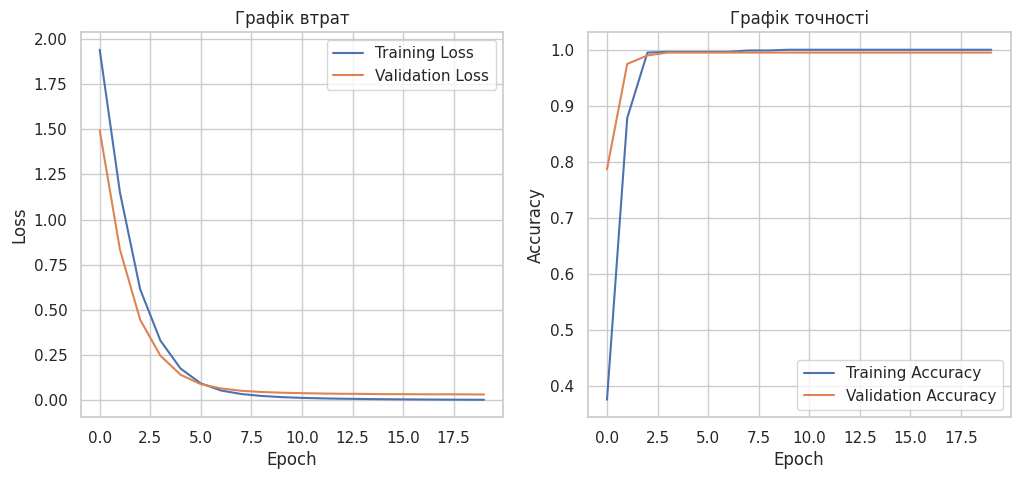

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        12
           3       1.00      0.99      1.00       111
           4       1.00      1.00      1.00        12
           5       1.00      1.00      1.00        13
           6       1.00      1.00      1.00        12
           7       0.92      1.00      0.96        12

    accuracy                           0.99       197
   macro avg       0.99      1.00      0.99       197
weighted avg       1.00      0.99      1.00       197



In [6]:
_target_col = "category"
_feature_cols = [
    c for c in flows.columns if c not in (_target_col, "label")
]
X = flows[_feature_cols]
y = flows[_target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

feature_scaler = StandardScaler()
X_train = pd.DataFrame(
    feature_scaler.fit_transform(X_train),
    columns=_feature_cols,
    index=X_train.index,
)
X_test = pd.DataFrame(
    feature_scaler.transform(X_test),
    columns=_feature_cols,
    index=X_test.index,
)

model = keras.Sequential([
    layers.Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dense(len(np.unique(y_train)), activation='softmax')
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_test, y_test))

loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Графік втрат')

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Графік точності')
plt.show()

y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
print(classification_report(y_test, y_pred_classes))

In [7]:
import joblib

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

keras_path = MODEL_DIR / "cyber_flow_classifier.keras"
model.save(keras_path)
print(f"Модель Keras: {keras_path.resolve()}")

artifacts_path = MODEL_DIR / "cyber_flow_artifacts.joblib"
joblib.dump(
    {
        "feature_scaler": feature_scaler,
        "label_encoder": _category_le,
        "feature_cols": _feature_cols,
        "label_order": list(LABEL_ORDER),
    },
    artifacts_path,
)
print(f"Scaler, encoder, колонки: {artifacts_path.resolve()}")

Модель Keras: /home/ivan/Projects/iit/models/cyber_flow_classifier.keras
Scaler, encoder, колонки: /home/ivan/Projects/iit/models/cyber_flow_artifacts.joblib
